# Od braków do pytań: pierwszy portret danych ankietowych

Ten notatnik jest punktem wyjścia do analizy przesłanych danych Stack Overflow. Najpierw liczymy braki, potem sprawdzamy jakość, poznajemy respondentów, technologie, AI i wynagrodzenia. **Wnioski liczbowe powstają podczas wykonania kodu**, więc zmienią się wraz z plikami wejściowymi.

Nie imputujemy odpowiedzi i nie usuwamy obserwacji z pliku źródłowego. Brak może oznaczać pominięcie pytania, filtr ankiety albo odmowę odpowiedzi; sam CSV nie pozwala rozstrzygnąć przyczyny. To opis respondentów, bez wag i bez podstaw do uogólnienia na wszystkich programistów. Nazwa repozytorium nie dowodzi roku przeprowadzenia badania.

**Uruchomienie:** wybierz interpreter ze środowiska projektu i wykonaj *Run All*. Potrzebne są oba pliki CSV w `data/raw/`. Wyniki i wykresy są osadzane w notatniku; nie eksportujemy danych respondentów.

In [1]:
from pathlib import Path
from html import unescape
import hashlib
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'requirements.txt').exists() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Uruchom notatnik z katalogu repozytorium lub notebooks/.')
DATA = ROOT / 'data/raw'
paths = [DATA / 'survey_results_public.csv', DATA / 'survey_results_schema.csv']
missing_files = [p.name for p in paths if not p.is_file()]
if missing_files:
    raise FileNotFoundError('Dodaj do data/raw/: ' + ', '.join(missing_files))
# Eksport używa NA jako znacznika braku. Inne napisy, np. None, pozostają odpowiedziami.
df = pd.read_csv(paths[0], low_memory=False, keep_default_na=False, na_values=['', 'NA'])
schema = pd.read_csv(paths[1], keep_default_na=False, na_values=['', 'NA'])
if df.empty:
    raise ValueError('Plik odpowiedzi jest pusty.')
raw = df.copy(deep=True)
N, P = df.shape
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_colwidth', 100)
def note(text):
    display(Markdown('**Co nam to mówi?** ' + text))
def question(col):
    match = schema.loc[schema['column'].eq(col), 'question']
    return unescape(str(match.iloc[0])) if len(match) else col
print(f'Wczytano {N:,} respondentów i {P} kolumn. Schemat: {len(schema)} pól.')

Wczytano 30,903 respondentów i 212 kolumn. Schemat: 212 pól.


## 1. Ile informacji brakuje?

Liczymy zarówno znaczniki braków z eksportu (`NA`, puste pole), jak i pola zawierające wyłącznie białe znaki. W pierwszej tabeli pokazujemy **wszystkie kolumny**. Odsetek braków ma zawsze mianownik równy liczbie respondentów. Nie traktujemy odpowiedzi „None”, „nie dotyczy” ani „wolę nie odpowiadać” automatycznie jako braku.

In [2]:
text_cols = df.select_dtypes(include=['object', 'string']).columns
blank_counts = pd.Series(0, index=df.columns, dtype='int64')
for col in text_cols:
    blank = df[col].notna() & df[col].astype('string').str.fullmatch(r'\s*', na=False)
    blank_counts[col] = int(blank.sum())
    df.loc[blank, col] = pd.NA
missing = pd.DataFrame({'braki_n': df.isna().sum(), 'odpowiedzi_n': df.notna().sum(),
                        'białe_znaki_n': blank_counts})
missing['braki_%'] = 100 * missing.braki_n / N
missing = missing.sort_values('braki_n', ascending=False)
with pd.option_context('display.max_rows', len(missing)):
    display(missing.round(2))
row_missing = df.isna().mean(axis=1) * 100
total_missing = int(df.isna().sum().sum())
note(f'Brakuje {total_missing:,} z {N * P:,} komórek ({100 * total_missing / (N * P):.1f}%). '
     f'Mediana odsetka braków w rekordzie wynosi {row_missing.median():.1f}%. '
     f'Całkowicie puste kolumny: {int((missing.odpowiedzi_n == 0).sum())}. '
     'To opis dostępności odpowiedzi, a nie dowód błędów zbierania danych.')

,braki_n,odpowiedzi_n,białe_znaki_n,braki_%
JobDifficultyAI_9,30903,0,0,100.00
JobEaseAI_7,30903,0,0,100.00
JobEaseAI_10,30903,0,0,100.00
JobEaseAI_9,30903,0,0,100.00
JobDifficultyAI_8,30903,0,0,100.00
JobDifficultyAI_10,30903,0,0,100.00
KnowledgeSource_14,30814,89,0,99.71
KnowledgeTime_14,30810,93,0,99.70
KnowledgeAcc_14,30805,98,0,99.68
AIMemAdmired,30778,125,0,99.60


**Co nam to mówi?** Brakuje 4,623,567 z 6,551,436 komórek (70.6%). Mediana odsetka braków w rekordzie wynosi 74.1%. Całkowicie puste kolumny: 6. To opis dostępności odpowiedzi, a nie dowód błędów zbierania danych.

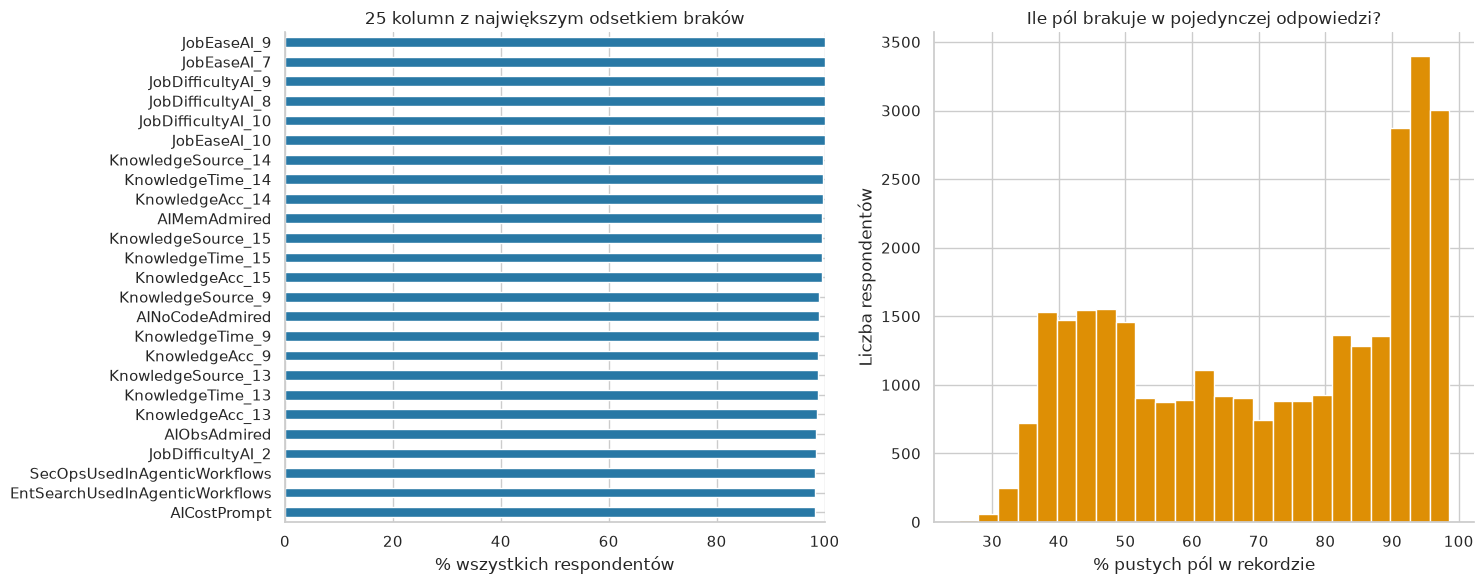

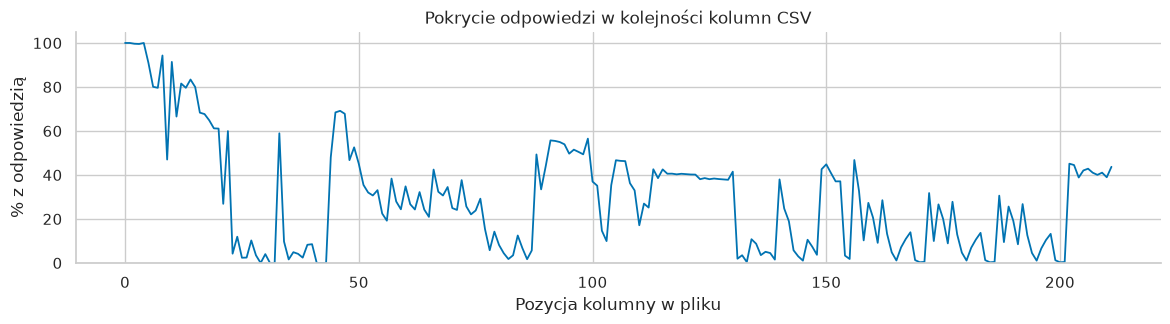

**Co nam to mówi?** Różnice pokrycia mogą wynikać z konstrukcji ankiety i pytań warunkowych. Spadek na osi kolumn nie dowodzi porzucenia ankiety: do takiej oceny potrzebne są reguły przejść i metadane sesji.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
missing.head(25)['braki_%'].sort_values().plot.barh(ax=axes[0], color='#2878a5')
axes[0].set(title='25 kolumn z największym odsetkiem braków', xlabel='% wszystkich respondentów')
axes[0].set_xlim(0, 100)
axes[1].hist(row_missing, bins=25, color='#de8f05', edgecolor='white')
axes[1].set(title='Ile pól brakuje w pojedynczej odpowiedzi?', xlabel='% pustych pól w rekordzie', ylabel='Liczba respondentów')
plt.tight_layout(); plt.show()
# Przekrój pokrycia pytań w kolejności kolumn; to nie rekonstrukcja ścieżki ankiety.
coverage = df.notna().mean().mul(100)
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(np.arange(P), coverage.values, linewidth=1.3)
ax.set(title='Pokrycie odpowiedzi w kolejności kolumn CSV', xlabel='Pozycja kolumny w pliku', ylabel='% z odpowiedzią', ylim=(0, 105))
plt.show()
note('Różnice pokrycia mogą wynikać z konstrukcji ankiety i pytań warunkowych. '
     'Spadek na osi kolumn nie dowodzi porzucenia ankiety: do takiej oceny potrzebne są reguły przejść i metadane sesji.')

## 2. Czy plik i słownik opisują ten sam zbiór?

Sprawdzamy nazwy pól, identyfikatory i liczbę niepustych odpowiedzi względem `nonmissing` w schemacie. Rozbieżność to sygnał do wyjaśnienia: schemat może pochodzić z innej wersji eksportu. Liczniki schematu porównujemy z surowym odczytem, przed normalizacją białych znaków.

In [4]:
if 'column' not in schema or schema['column'].isna().any() or schema['column'].duplicated().any():
    raise ValueError('Schemat musi mieć unikalne, niepuste nazwy w polu column.')
expected = set(schema['column'])
missing_cols = sorted(expected - set(df.columns))
extra_cols = sorted(set(df.columns) - expected)
checks = []
def check(name, value, meaning):
    checks.append({'kontrola': name, 'liczba': int(value), 'interpretacja': meaning})
check('Kolumny ze schematu nieobecne w danych', len(missing_cols), str(missing_cols))
check('Kolumny danych nieobecne w schemacie', len(extra_cols), str(extra_cols))
check('Pełne duplikaty wierszy', raw.duplicated().sum(), 'Kandydaci do sprawdzenia, bez automatycznego usuwania')
if 'ResponseId' in df:
    check('Puste ResponseId', df.ResponseId.isna().sum(), 'Identyfikator powinien być wypełniony')
    check('Powtórzone niepuste ResponseId', df.loc[df.ResponseId.notna(), 'ResponseId'].duplicated().sum(), 'Wymaga wyjaśnienia')
    payload = df.drop(columns='ResponseId')
    check('Identyczne odpowiedzi po pominięciu ID', payload.duplicated().sum(), 'Identyczne odpowiedzi nie dowodzą tej samej osoby')
quality = pd.DataFrame(checks)
display(quality)
if 'nonmissing' in schema:
    reconciliation = schema[['column', 'nonmissing']].set_index('column').rename(columns={'nonmissing': 'schemat_n'})
    reconciliation['plik_n'] = raw.notna().sum()
    reconciliation['różnica'] = reconciliation['plik_n'] - pd.to_numeric(reconciliation['schemat_n'], errors='coerce')
    mismatches = reconciliation[reconciliation['różnica'].isna() | reconciliation['różnica'].ne(0)]
    display(mismatches)
    note(f'{len(mismatches)} pól ma niezgodny lub nieporównywalny licznik odpowiedzi ze schematem. '
         'Zgodne liczniki zwiększają zaufanie do dopasowania wersji, ale nie weryfikują poprawności pojedynczych wartości.')

,kontrola,liczba,interpretacja
0,Kolumny ze schematu nieobecne w danych,0,[]
1,Kolumny danych nieobecne w schemacie,0,[]
2,Pełne duplikaty wierszy,0,"Kandydaci do sprawdzenia, bez automatycznego usuwania"
3,Puste ResponseId,0,Identyfikator powinien być wypełniony
4,Powtórzone niepuste ResponseId,0,Wymaga wyjaśnienia
5,Identyczne odpowiedzi po pominięciu ID,1055,Identyczne odpowiedzi nie dowodzą tej samej osoby


,schemat_n,plik_n,różnica
column,,,


**Co nam to mówi?** 0 pól ma niezgodny lub nieporównywalny licznik odpowiedzi ze schematem. Zgodne liczniki zwiększają zaufanie do dopasowania wersji, ale nie weryfikują poprawności pojedynczych wartości.

## 3. Czy liczby mają sens?

Zachowujemy dane oryginalne, a wartości liczbowe tworzymy w osobnej ramce. Dla doświadczenia odpowiedzi „Less than 1 year” i „More than 50 years” oznaczamy orientacyjnie jako 0,5 i 51. To przybliżenia do wykresów, nie dokładne pomiary. Nie wymuszamy reguły `WorkExp ≤ YearsCode`: doświadczenie zawodowe może obejmować inne zawody.

Wartości ujemne i skrajnie duże doświadczenie są flagami do przeglądu, nie podstawą do cichego kasowania rekordów. Nie zakładamy skali `JobSat` bez sprawdzenia jej wartości.

In [5]:
num = pd.DataFrame(index=df.index)
parse_report = []
for col in ['YearsCode', 'WorkExp', 'ToolCount', 'AIToolCount', 'Compensation', 'ConvertedCompYearly']:
    if col not in df:
        continue
    s = df[col].astype('string').str.strip()
    s = s.replace({'Less than 1 year': '0.5', 'More than 50 years': '51'})
    num[col] = pd.to_numeric(s, errors='coerce').astype(float)
    failed = df[col].notna() & num[col].isna()
    parse_report.append({'pole': col, 'niepuste_n': int(df[col].notna().sum()),
                         'nieprzekonwertowane_n': int(failed.sum()),
                         'przykłady': ', '.join(df.loc[failed, col].astype(str).unique()[:5]),
                         'ujemne_n': int(num[col].lt(0).sum()),
                         'nieskończone_n': int(np.isinf(num[col]).sum())})
display(pd.DataFrame(parse_report))
num = num.replace([np.inf, -np.inf], np.nan)
if not num.empty:
    display(num.describe(percentiles=[.01, .25, .5, .75, .95, .99]).T.round(2))
for col in ['YearsCode', 'WorkExp']:
    if col in num:
        print(f'{col}: poza orientacyjnym zakresem 0–80 lat: {int((num[col].lt(0) | num[col].gt(80)).sum())}')
if 'JobSat' in df:
    display(df['JobSat'].value_counts(dropna=False).rename('liczba').to_frame())
note('Przed modelowaniem trzeba rozstrzygnąć flagi jakości, jednostki i znaczenie kategorii. '
     'Nieprzekonwertowane wartości pozostają widoczne w raporcie; nie zastępujemy ich zerem.')

,pole,niepuste_n,nieprzekonwertowane_n,przykłady,ujemne_n,nieskończone_n
0,YearsCode,25204,0,,0,0
1,WorkExp,24607,0,,0,0
2,ToolCount,14836,0,,0,0
3,AIToolCount,11919,0,,0,0
4,Compensation,14447,0,,0,0
5,ConvertedCompYearly,13507,0,,0,0


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
YearsCode,25204.0,1.733000e+01,1.203000e+01,1.0,1.0,8.0,15.0,25.0,40.0,50.00,1.000000e+02
WorkExp,24607.0,1.426000e+01,1.173000e+01,1.0,1.0,5.0,12.0,20.0,36.0,48.00,1.000000e+02
ToolCount,14836.0,3.487000e+01,4.789400e+02,0.0,0.0,4.0,6.0,10.0,20.0,59.30,1.000000e+04
AIToolCount,11919.0,9.230786e+10,9.205284e+12,0.0,1.0,2.0,2.0,3.0,5.0,12.00,1.000000e+15
Compensation,14447.0,6.921852e+101,8.319767e+103,0.0,0.0,50000.0,100000.0,200000.0,3000000.0,57620000.00,1.000000e+106
ConvertedCompYearly,13507.0,1.065351e+05,4.453677e+05,1.0,32.0,41372.0,79610.0,126347.0,240000.0,488593.72,3.191935e+07


YearsCode: poza orientacyjnym zakresem 0–80 lat: 25
WorkExp: poza orientacyjnym zakresem 0–80 lat: 39


,liczba
JobSat,
NaN,12027
8.0,4534
7.0,3982
9.0,2383
6.0,2316
10.0,1816
5.0,1483
3.0,754
4.0,713


**Co nam to mówi?** Przed modelowaniem trzeba rozstrzygnąć flagi jakości, jednostki i znaczenie kategorii. Nieprzekonwertowane wartości pozostają widoczne w raporcie; nie zastępujemy ich zerem.

## 4. Kto odpowiedział? Portret próby

Dla pól pojedynczego wyboru podajemy liczbę odpowiedzi i procent **osób z niepustą odpowiedzią na dane pytanie**. Kategorie pozostają w języku oryginalnej ankiety. Tabele i wykresy pokazują największe kategorie; pełne liczności można odczytać z `df[col].value_counts()`.

Jeżeli pytanie dopuszcza wiele wskazań, liczymy osoby wskazujące kategorię, a nie kombinacje odpowiedzi. Każda osoba jest liczona najwyżej raz dla danego wyboru. Suma udziałów może przekroczyć 100%.

### `Country` — Where do you live?

Podstawa: 21,370/30,903 respondentów (69.2% próby).


,osoby_n,% odpowiadających
kategoria,,
United States of America,4755,22.3
Germany,1983,9.3
United Kingdom of Great Britain and Northern Ireland,1374,6.4
India,1309,6.1
Canada,851,4.0
France,794,3.7
Netherlands,577,2.7
Poland,527,2.5
Australia,522,2.4


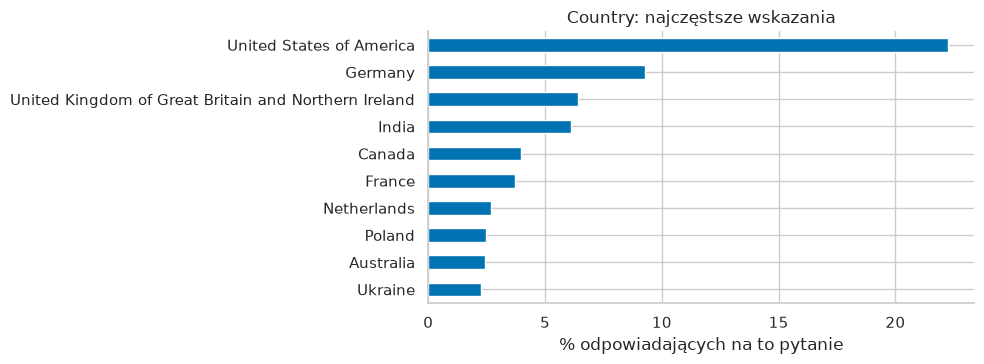

**Co nam to mówi?** Najczęstsze wskazanie to **United States of America**: 4,755 osób (22.3% odpowiadających). Pokrycie pytania to 69.2% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `Age` — What is your age?

Podstawa: 30,903/30,903 respondentów (100.0% próby).


,osoby_n,% odpowiadających
kategoria,,
25-34 years old,9267,30.0
35-44 years old,8522,27.6
18-24 years old,4944,16.0
45-54 years old,4198,13.6
55-64 years old,1829,5.9
Under 18 years old,969,3.1
65 years or older,822,2.7
Prefer not to say,352,1.1


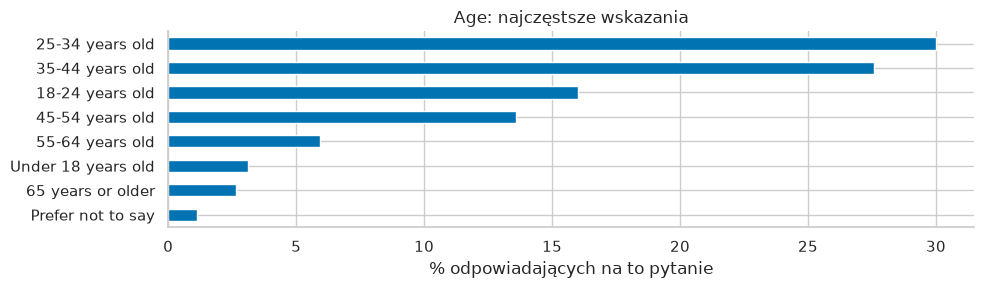

**Co nam to mówi?** Najczęstsze wskazanie to **25-34 years old**: 9,267 osób (30.0% odpowiadających). Pokrycie pytania to 100.0% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `Education` — Which of the following best describes the highest level of formal education that you've completed?

Podstawa: 30,761/30,903 respondentów (99.5% próby).


,osoby_n,% odpowiadających
kategoria,,
"Bachelor's degree (B.A., B.S., B.Eng., etc.)",12396,40.3
"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",7990,26.0
Some college/university study without earning a degree,3813,12.4
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",2431,7.9
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",1812,5.9
"Associate degree (A.A., A.S., etc.)",942,3.1
Primary/elementary school,706,2.3
"Other, please specify",671,2.2


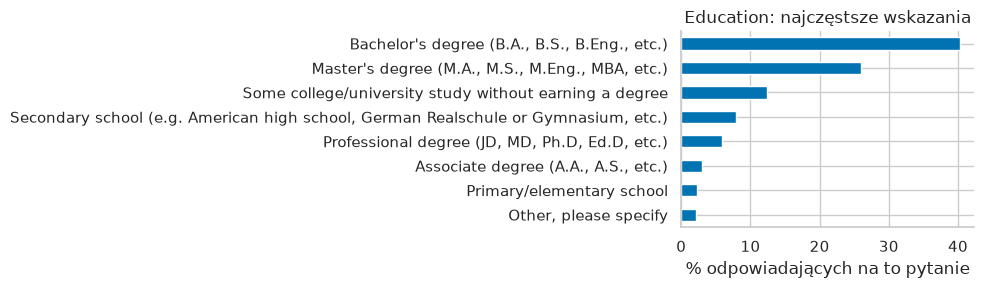

**Co nam to mówi?** Najczęstsze wskazanie to **Bachelor's degree (B.A., B.S., B.Eng., etc.)**: 12,396 osób (40.3% odpowiadających). Pokrycie pytania to 99.5% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `Employment` — Which of the following best describes your current employment status?

Podstawa: 30,903/30,903 respondentów (100.0% próby).


,osoby_n,% odpowiadających
kategoria,,
Employed,20259,65.6
"Independent contractor, freelancer, or self-employed",4607,14.9
Student,3139,10.2
Not employed,1742,5.6
Retired,607,2.0
I prefer not to say,549,1.8


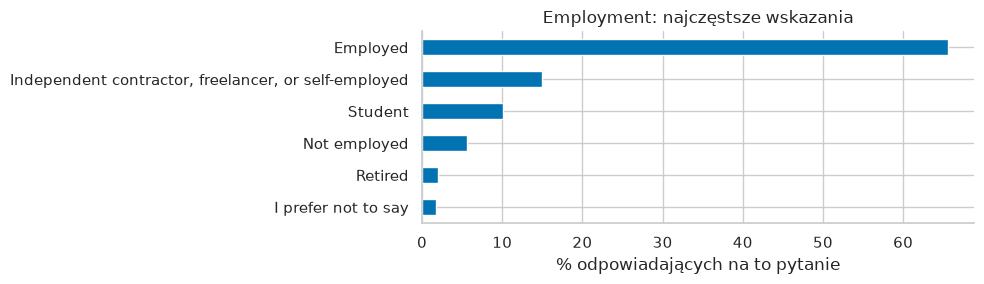

**Co nam to mówi?** Najczęstsze wskazanie to **Employed**: 20,259 osób (65.6% odpowiadających). Pokrycie pytania to 100.0% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `Role` — Which of the following best describes your current role, or the role you held for the most time in the past year?

Podstawa: 25,767/30,903 respondentów (83.4% próby).


,osoby_n,% odpowiadających
kategoria,,
"Developer, full-stack",7042,27.3
"Developer, back-end",3473,13.5
Student,1823,7.1
"Architect, software or solutions",1792,7.0
"Developer, desktop or enterprise applications",1030,4.0
"Developer, front-end",933,3.6
"Developer, embedded applications or devices",731,2.8
Academic researcher,705,2.7
"Developer, mobile",685,2.7


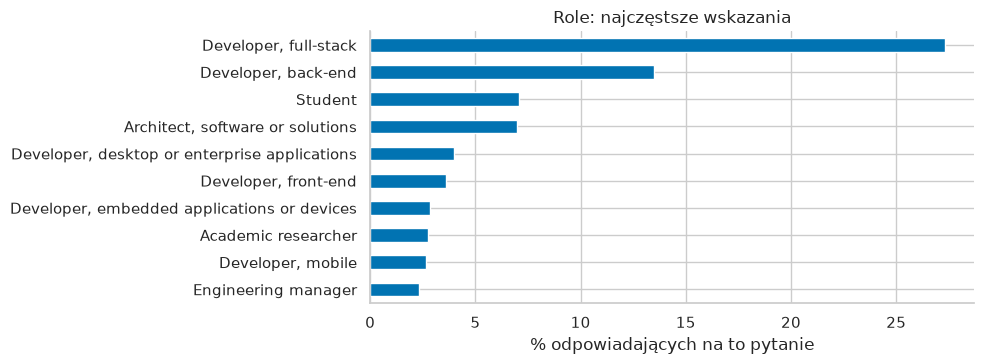

**Co nam to mówi?** Najczęstsze wskazanie to **Developer, full-stack**: 7,042 osób (27.3% odpowiadających). Pokrycie pytania to 83.4% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `WorkSetting` — Which best describes your current work situation?

Podstawa: 24,602/30,903 respondentów (79.6% próby).


,osoby_n,% odpowiadających
kategoria,,
Remote,8564,34.8
"Hybrid (some remote, leans heavy to in-person)",4883,19.8
In-person,4335,17.6
"Hybrid (some in-person, leans heavy to flexibility)",3823,15.5
"Your choice (very flexible, you can come in when you want or just as needed)",2997,12.2


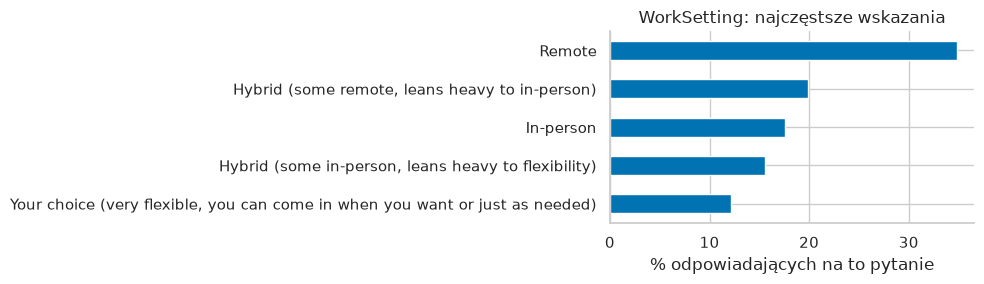

**Co nam to mówi?** Najczęstsze wskazanie to **Remote**: 8,564 osób (34.8% odpowiadających). Pokrycie pytania to 79.6% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

In [6]:
def selection_counts(col):
    s = df[col].dropna().astype(str)
    base = len(s)
    tokens = s.str.split(';').explode().str.strip()
    tokens = tokens[tokens.ne('')]
    # Indeks to respondent; deduplikacja wskazań w obrębie osoby.
    pairs = pd.DataFrame({'respondent': tokens.index, 'kategoria': tokens.values}).drop_duplicates()
    counts = pairs['kategoria'].value_counts()
    return counts, base

def category_table(col, limit=12):
    counts, base = selection_counts(col)
    table = counts.rename('osoby_n').to_frame()
    table['% odpowiadających'] = 100 * table['osoby_n'] / base if base else np.nan
    display(Markdown(f'### `{col}` — {question(col)}'))
    print(f'Podstawa: {base:,}/{N:,} respondentów ({100 * base/N:.1f}% próby).')
    if table.empty:
        print('Brak odpowiedzi.'); return table
    display(table.head(limit).round(1))
    fig, ax = plt.subplots(figsize=(10, max(3, min(limit, len(table)) * .38)))
    table.head(limit)['% odpowiadających'].sort_values().plot.barh(ax=ax)
    ax.set(xlabel='% odpowiadających na to pytanie', ylabel='', title=f'{col}: najczęstsze wskazania')
    plt.tight_layout(); plt.show()
    top = table.index[0]
    note(f'Najczęstsze wskazanie to **{top}**: {table.iloc[0,0]:,.0f} osób '
         f'({table.iloc[0,1]:.1f}% odpowiadających). Pokrycie pytania to {100 * base/N:.1f}% próby; '
         'ten ranking opisuje respondentów, a nie strukturę całego rynku.')
    return table

profiles = {}
for col in ['Country', 'Age', 'Education', 'Employment', 'Role', 'WorkSetting']:
    if col in df:
        profiles[col] = category_table(col, limit=10)

## 5. Doświadczenie: szeroki przekrój czy jedna grupa?

Porównujemy rozkłady lat kodowania i pracy zawodowej. Wykresy obejmują wyłącznie wartości liczbowe z orientacyjnego zakresu 0–80; wcześniejszy raport pokazuje wartości spoza zakresu. Niczego nie usuwamy z `df`. Mediana jest mniej podatna na skrajne odpowiedzi niż średnia.

**Co nam to mówi?** **YearsCode**: mediana 15.0 lat, środkowe 50% 8.0–25.0 lat; wykres obejmuje 81.5% próby.

**Co nam to mówi?** **WorkExp**: mediana 12.0 lat, środkowe 50% 5.0–20.0 lat; wykres obejmuje 79.5% próby.

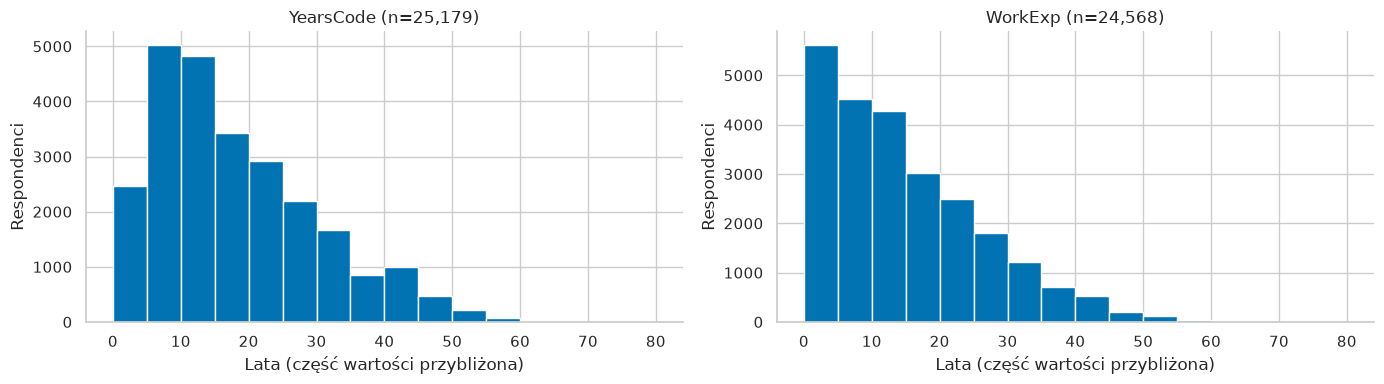

In [7]:
exp_cols = [col for col in ['YearsCode', 'WorkExp'] if col in num]
if exp_cols:
    fig, axes = plt.subplots(1, len(exp_cols), figsize=(7 * len(exp_cols), 4), squeeze=False)
    for col, ax in zip(exp_cols, axes.flat):
        values = num.loc[num[col].between(0, 80), col]
        ax.hist(values, bins=np.arange(0, 85, 5), edgecolor='white')
        ax.set(title=f'{col} (n={len(values):,})', xlabel='Lata (część wartości przybliżona)', ylabel='Respondenci')
        if len(values):
            note(f'**{col}**: mediana {values.median():.1f} lat, środkowe 50% '
                 f'{values.quantile(.25):.1f}–{values.quantile(.75):.1f} lat; '
                 f'wykres obejmuje {100 * len(values)/N:.1f}% próby.')
    plt.tight_layout(); plt.show()

## 6. Technologie: czego używają, a czego chcą używać?

Dane wielokrotnego wyboru rozbijamy po średnikach. Porównujemy odsetki wśród odpowiadających na **każde pytanie osobno**; podstawy mogą być różne. Różnica procentów nie jest prognozą wzrostu rynku ani dowodem zmiany preferencji konkretnej osoby.

### `LanguagesHaveWorkedWith` — Which programming, scripting, and markup languages have you done extensive development work in over the past year, which do you want to work with over the next year, and which have you used AI tools or AI agents to work with? Select all that apply in each row.

Podstawa: 13,924/30,903 respondentów (45.1% próby).


,osoby_n,% odpowiadających
kategoria,,
JavaScript,8742,62.8
SQL,8237,59.2
HTML/CSS,8211,59.0
Python,8182,58.8
Bash/Shell (all shells),7231,51.9
TypeScript,6169,44.3
Java,3884,27.9
C#,3818,27.4
PowerShell,3472,24.9


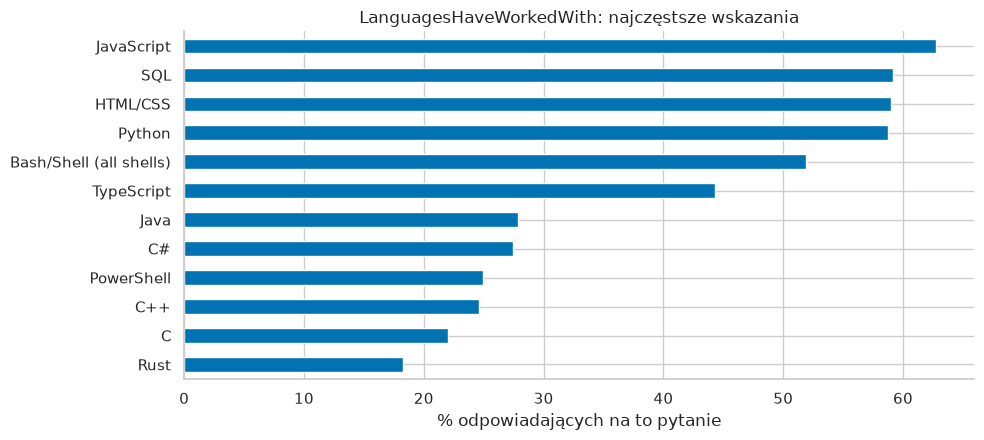

**Co nam to mówi?** Najczęstsze wskazanie to **JavaScript**: 8,742 osób (62.8% odpowiadających). Pokrycie pytania to 45.1% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `DatabasesHaveWorkedWith` — Which database environments have you done extensive development work in over the past year? Which do you want to work in over the next year? If you worked with the database and want to continue to do so, please check both boxes in that row.

Podstawa: 11,852/30,903 respondentów (38.4% próby).


,osoby_n,% odpowiadających
kategoria,,
PostgreSQL,6983,58.9
SQLite,5081,42.9
MySQL,4235,35.7
Redis,3414,28.8
Microsoft SQL Server,3270,27.6
MariaDB,2446,20.6
MongoDB,2297,19.4
Elasticsearch,1784,15.1
Oracle,1133,9.6


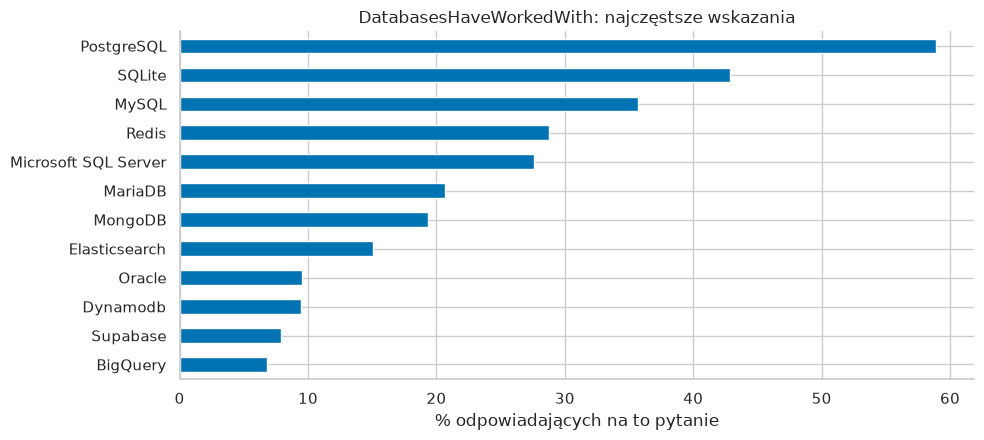

**Co nam to mówi?** Najczęstsze wskazanie to **PostgreSQL**: 6,983 osób (58.9% odpowiadających). Pokrycie pytania to 38.4% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `WebFrameworkHaveWorkedWith` — Which web frameworks and web technologies have you done extensive development work in over the past year? Which do you want to work in over the next year? If you worked with the framework and want to continue to do so, please check both boxes in that row.

Podstawa: 9,957/30,903 respondentów (32.2% próby).


,osoby_n,% odpowiadających
kategoria,,
Node.js,4769,47.9
React,4263,42.8
Next.js,2117,21.3
ASP.NET Core,2045,20.5
jQuery,2028,20.4
FastAPI,1903,19.1
Vue.js,1773,17.8
Angular,1642,16.5
Express,1604,16.1


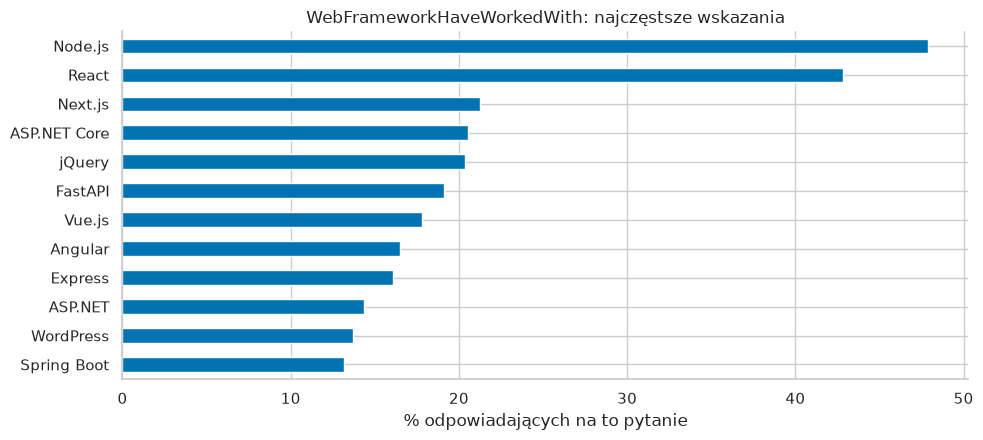

**Co nam to mówi?** Najczęstsze wskazanie to **Node.js**: 4,769 osób (47.9% odpowiadających). Pokrycie pytania to 32.2% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `LLMHaveWorkedWith` — Which LLM model vendors for AI tools have you used for work in the past year? Which would you like to use next year? Select all that apply.

Podstawa: 11,637/30,903 respondentów (37.7% próby).


,osoby_n,% odpowiadających
kategoria,,
Anthropic,8869,76.2
OpenAI,8833,75.9
Google AI,6483,55.7
Microsoft,3142,27.0
DeepSeek,2251,19.3
Alibaba Qwen,1203,10.3
Mistral AI,1162,10.0
xAI,895,7.7
Meta AI,754,6.5


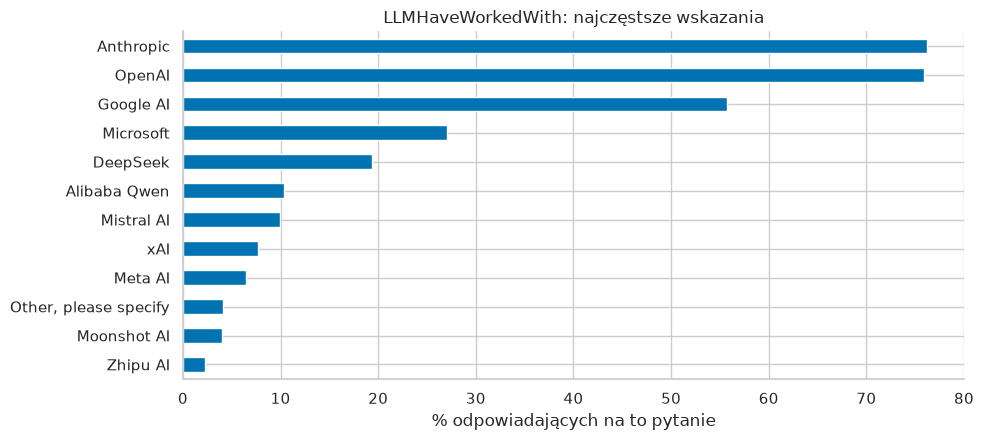

**Co nam to mówi?** Najczęstsze wskazanie to **Anthropic**: 8,869 osób (76.2% odpowiadających). Pokrycie pytania to 37.7% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

,używali_n,chcą_n,używali_%,chcą_%,różnica_pp
kategoria,,,,,
JavaScript,8742,3917,62.8,35.7,-27.0
SQL,8237,4512,59.2,41.2,-18.0
HTML/CSS,8211,4081,59.0,37.2,-21.7
Python,8182,4712,58.8,43.0,-15.8
Bash/Shell (all shells),7231,3640,51.9,33.2,-18.7
TypeScript,6169,3877,44.3,35.4,-8.9
Java,3884,1849,27.9,16.9,-11.0
C#,3818,2325,27.4,21.2,-6.2
PowerShell,3472,1222,24.9,11.2,-13.8


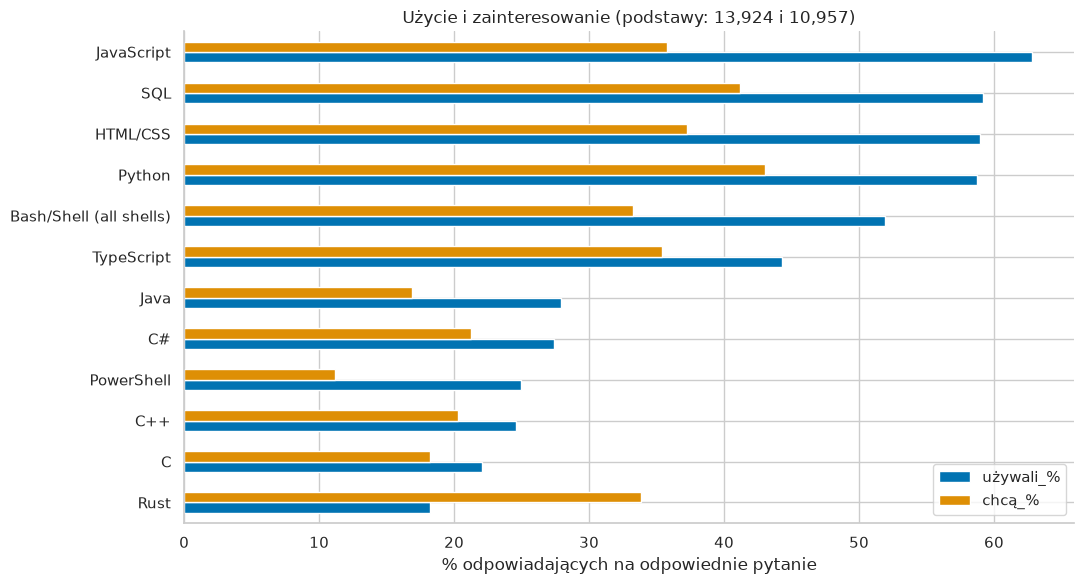

**Te same osoby: JavaScript, n=10,884 kompletnych par**

,Nie wskazał chęci,Wskazał chęć
Nie wskazał użycia,3839,214
Wskazał użycie,3157,3674


**Co nam to mówi?** Tabela par ogranicza problem różnych podstaw. Brak wskazania technologii oznacza brak wyboru w tym pytaniu, a nie pewność, że osoba nigdy jej nie używała.

In [8]:
technology_tables = {}
for col in ['LanguagesHaveWorkedWith', 'DatabasesHaveWorkedWith', 'WebFrameworkHaveWorkedWith', 'LLMHaveWorkedWith']:
    if col in df:
        technology_tables[col] = category_table(col, limit=12)

have, want = 'LanguagesHaveWorkedWith', 'LanguagesWantToWorkWith'
if have in df and want in df:
    hc, hn = selection_counts(have)
    wc, wn = selection_counts(want)
    comparison = pd.concat([hc.rename('używali_n'), wc.rename('chcą_n')], axis=1).fillna(0)
    comparison['używali_%'] = comparison['używali_n'] / hn * 100 if hn else np.nan
    comparison['chcą_%'] = comparison['chcą_n'] / wn * 100 if wn else np.nan
    comparison['różnica_pp'] = comparison['chcą_%'] - comparison['używali_%']
    display(comparison.sort_values('używali_n', ascending=False).head(20).round(1))
    if hn and wn:
        chosen = comparison.nlargest(12, 'używali_n').sort_values('używali_%')
        chosen[['używali_%', 'chcą_%']].plot.barh(figsize=(11, 6))
        plt.xlabel('% odpowiadających na odpowiednie pytanie'); plt.ylabel('')
        plt.title(f'Użycie i zainteresowanie (podstawy: {hn:,} i {wn:,})')
        plt.tight_layout(); plt.show()
        # Porównanie tych samych osób, bez traktowania braków jako „nie”.
        paired = df[[have, want]].dropna()
        tech = hc.index[0] if len(hc) else None
        if tech is not None and len(paired):
            def contains(s, item):
                return s.astype(str).str.split(';').map(lambda x: item in {v.strip() for v in x})
            cross = pd.crosstab(contains(paired[have], tech), contains(paired[want], tech)).reindex(index=[False,True], columns=[False,True], fill_value=0)
            cross.index = ['Nie wskazał użycia', 'Wskazał użycie']
            cross.columns = ['Nie wskazał chęci', 'Wskazał chęć']
            display(Markdown(f'**Te same osoby: {tech}, n={len(paired):,} kompletnych par**'))
            display(cross)
            note('Tabela par ogranicza problem różnych podstaw. Brak wskazania technologii oznacza brak wyboru '
                 'w tym pytaniu, a nie pewność, że osoba nigdy jej nie używała.')

## 7. AI: deklarowane użycie i zaufanie

Najpierw pokazujemy osobno używanie AI, nastawienie i zaufanie. Użycie nie oznacza zaufania; sprawdzamy ich współwystępowanie. Przekrój wieku i zaufania opisuje zależność, bez wniosku o przyczynowości.

### `AISelect` — Do you currently use AI tools or AI agents in your role at work?

Podstawa: 17,464/30,903 respondentów (56.5% próby).


,osoby_n,% odpowiadających
kategoria,,
AI coding assistants or coding agents,11509,65.9
General-purpose AI chat tools,10920,62.5
AI agents or automated workflows,4582,26.2
Internal AI tools built by my company,3115,17.8
I don’t use AI tools,3003,17.2


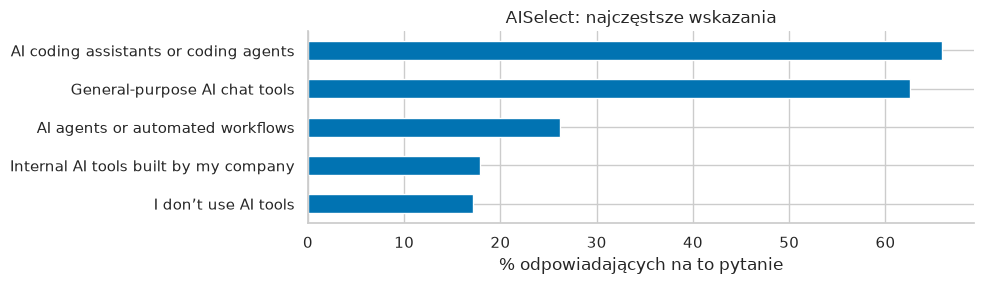

**Co nam to mówi?** Najczęstsze wskazanie to **AI coding assistants or coding agents**: 11,509 osób (65.9% odpowiadających). Pokrycie pytania to 56.5% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `AISentiment` — How would you describe your attitude toward using AI tools or agents as part of your work?

Podstawa: 14,428/30,903 respondentów (46.7% próby).


,osoby_n,% odpowiadających
kategoria,,
Very favorable,4564,31.6
Somewhat favorable,4385,30.4
Neutral,2205,15.3
Somewhat unfavorable,2110,14.6
Very unfavorable,994,6.9
Not sure,170,1.2


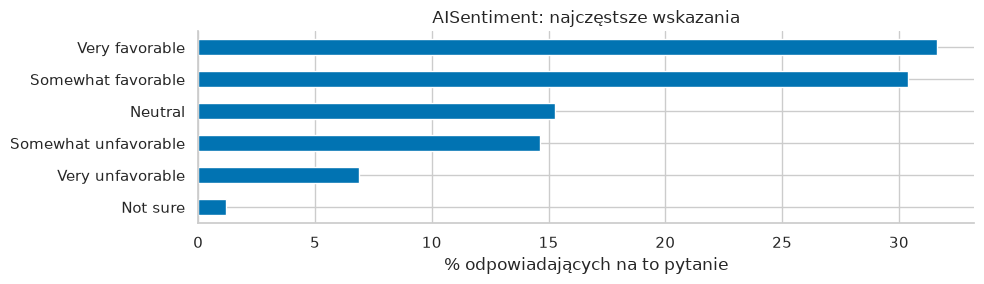

**Co nam to mówi?** Najczęstsze wskazanie to **Very favorable**: 4,564 osób (31.6% odpowiadających). Pokrycie pytania to 46.7% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

### `AITrust` — How much do you trust the output from AI tools or AI agents as part of your workflow?

Podstawa: 14,304/30,903 respondentów (46.3% próby).


,osoby_n,% odpowiadających
kategoria,,
I trust it when I can easily verify the output,6872,48.0
"I trust it for many tasks, but not important work decisions",2329,16.3
I trust it for low-risk work tasks only,2326,16.3
I do not trust it for most work tasks,1754,12.3
"I trust it for many tasks, including important work decisions",949,6.6
Not sure / I do not use AI tools,74,0.5


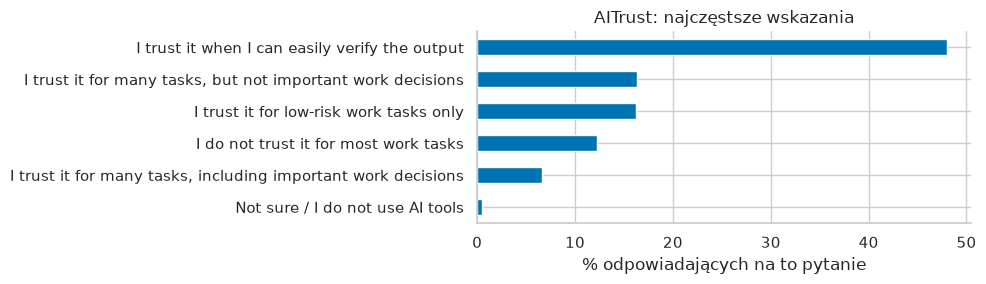

**Co nam to mówi?** Najczęstsze wskazanie to **I trust it when I can easily verify the output**: 6,872 osób (48.0% odpowiadających). Pokrycie pytania to 46.3% próby; ten ranking opisuje respondentów, a nie strukturę całego rynku.

,podstawa_n
Age,
18-24 years old,1709
25-34 years old,4085
35-44 years old,4332
45-54 years old,2338
55-64 years old,1060
65 years or older,419
Under 18 years old,279


/tmp/ipykernel_2645/3081684558.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


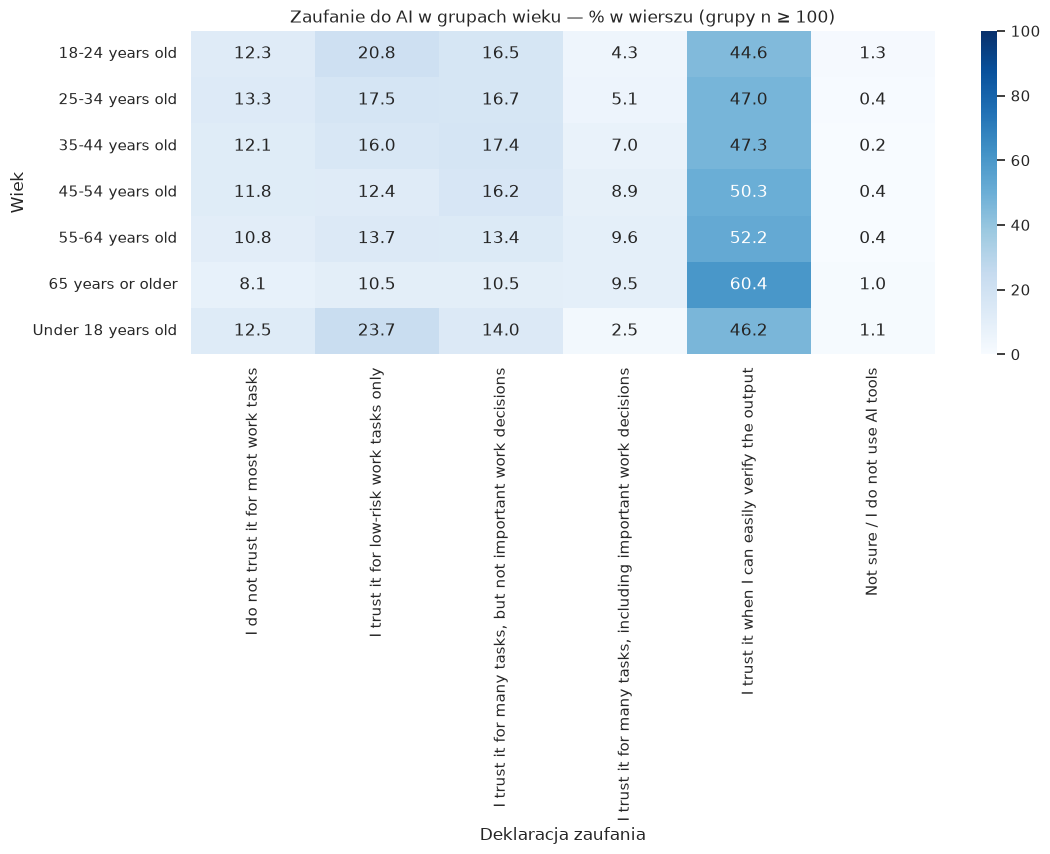

**Co nam to mówi?** Przekrój opiera się na 14,304 kompletnych parach; pokazano 7 grup o n ≥ 100. Wiersze mają różne podstawy. Różnice mogą współwystępować z rolą, doświadczeniem i krajem; nie pozwalają przypisać wpływu samemu wiekowi.

In [9]:
ai_tables = {}
for col in ['AISelect', 'AISentiment', 'AITrust']:
    if col in df:
        ai_tables[col] = category_table(col, limit=15)
if {'Age', 'AITrust'}.issubset(df.columns):
    pair = df[['Age', 'AITrust']].dropna()
    counts = pd.crosstab(pair.Age, pair.AITrust)
    eligible = counts.sum(axis=1).ge(100)
    counts = counts.loc[eligible]
    if not counts.empty:
        percentages = counts.div(counts.sum(axis=1), axis=0) * 100
        display(counts.sum(axis=1).rename('podstawa_n').to_frame())
        fig, ax = plt.subplots(figsize=(12, max(3, len(counts)*.6)))
        sns.heatmap(percentages, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax)
        ax.set(title='Zaufanie do AI w grupach wieku — % w wierszu (grupy n ≥ 100)', xlabel='Deklaracja zaufania', ylabel='Wiek')
        plt.tight_layout(); plt.show()
        note(f'Przekrój opiera się na {len(pair):,} kompletnych parach; pokazano {len(counts)} grup o n ≥ 100. '
             'Wiersze mają różne podstawy. Różnice mogą współwystępować z rolą, doświadczeniem i krajem; '
             'nie pozwalają przypisać wpływu samemu wiekowi.')

## 8. Wynagrodzenia: najpierw jednostki i selekcja

Nie porównujemy surowego `Compensation` między walutami. Schemat opisuje `ConvertedCompYearly` jako kwotę roczną przeliczoną na USD, ale nie dokumentuje tutaj pełnej procedury kursowej ani filtrów publikacyjnych. Dlatego traktujemy wyniki jako eksploracyjne.

Pokazujemy wszystkie skończone dodatnie kwoty w USD, ze skalą logarytmiczną; zera, liczby ujemne, braki i błędy konwersji nie trafiają do tego wykresu. Nie odcinamy wysokich dochodów bez uzasadnienia. Porównania krajów obejmują tylko grupy z co najmniej 100 dodatnimi kwotami, a każda tabela podaje także pokrycie odpowiedzi.

,liczba
wszyscy_n,30903
dodatnie_USD_n,13507
zera_n,0
ujemne_n,0
brak_lub_błąd_n,17396


,USD_rocznie
count,13507.00
mean,106535.07
std,445367.66
min,1.00
1%,32.00
25%,41372.00
50%,79610.00
75%,126347.00
95%,240000.00
99%,488593.72


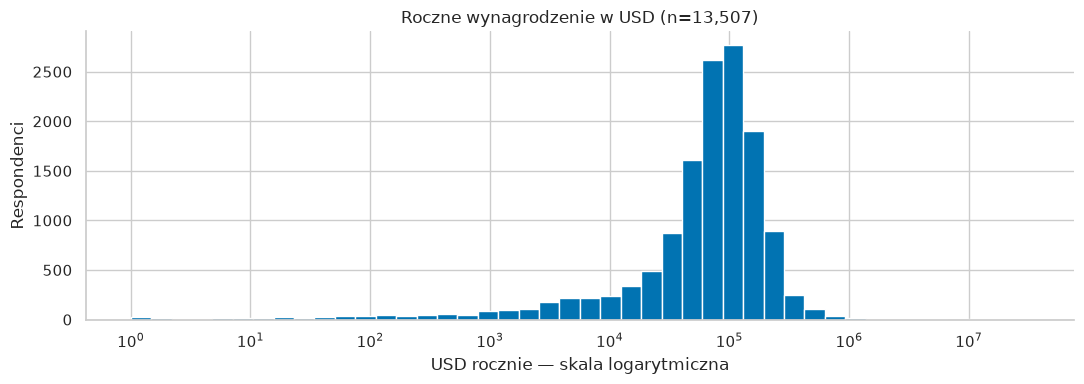

**Co nam to mówi?** Mediana dodatnich kwot wynosi 79,610 USD rocznie, a średnia 106,535 USD. Podstawa to 43.7% całej próby. To wynik wyselekcjonowanej grupy odpowiadających, a nie oszacowanie pensji wszystkich respondentów.

,respondenci_n,kwoty_n,mediana_USD,Q1_USD,Q3_USD,pokrycie_%
Country,,,,,,
United States of America,4755,3181,150000.0,104000.0,200000.0,66.9
Germany,1983,1343,81884.0,60535.5,104630.0,67.7
United Kingdom of Great Britain and Northern Ireland,1374,918,93098.0,66499.0,132997.0,66.8
Canada,851,597,92188.0,65241.0,127645.0,70.2
France,794,560,60276.0,45491.0,85296.0,70.5
India,1309,552,16713.0,6267.0,34533.8,42.2
Netherlands,577,377,79610.0,58957.0,108428.0,65.3
Spain,453,357,68237.0,46629.0,96669.0,78.8
Australia,522,338,103156.0,78761.0,125982.8,64.8


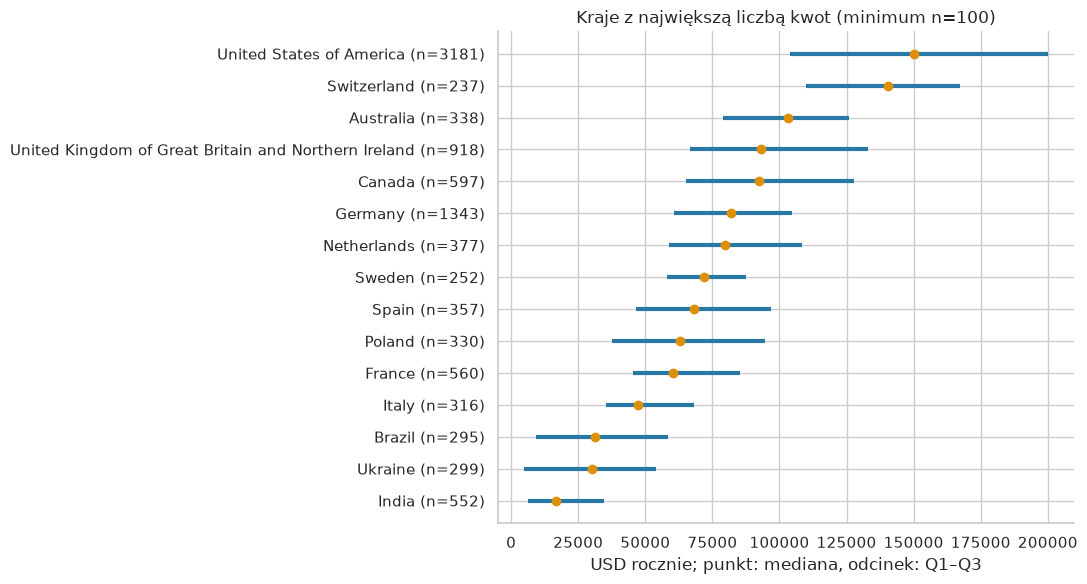

**Co nam to mówi?** Porównanie jest nominalne: bez kosztów życia, parytetu siły nabywczej, roli i stażu. Nierówne pokrycie odpowiedzi dodatkowo ogranicza porównywalność krajów.

In [10]:
if 'ConvertedCompYearly' in num:
    salary = num['ConvertedCompYearly']
    positive = salary[salary.gt(0)]
    display(pd.Series({'wszyscy_n': N, 'dodatnie_USD_n': len(positive),
                       'zera_n': int(salary.eq(0).sum()), 'ujemne_n': int(salary.lt(0).sum()),
                       'brak_lub_błąd_n': int(salary.isna().sum())}).rename('liczba').to_frame())
    if len(positive):
        display(positive.describe(percentiles=[.01,.25,.5,.75,.95,.99]).rename('USD_rocznie').to_frame().round(2))
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.hist(positive, bins=np.geomspace(positive.min(), positive.max(), 45) if positive.nunique()>1 else 5, edgecolor='white')
        ax.set_xscale('log')
        ax.set(title=f'Roczne wynagrodzenie w USD (n={len(positive):,})', xlabel='USD rocznie — skala logarytmiczna', ylabel='Respondenci')
        plt.tight_layout(); plt.show()
        note(f'Mediana dodatnich kwot wynosi {positive.median():,.0f} USD rocznie, a średnia {positive.mean():,.0f} USD. '
             f'Podstawa to {100*len(positive)/N:.1f}% całej próby. To wynik wyselekcjonowanej grupy '
             'odpowiadających, a nie oszacowanie pensji wszystkich respondentów.')
    if 'Country' in df:
        country_salary = pd.DataFrame({'Country': df.Country, 'USD': salary.where(salary.gt(0))})
        country_summary = country_salary.groupby('Country', observed=True).agg(
            respondenci_n=('USD','size'), kwoty_n=('USD','count'), mediana_USD=('USD','median'),
            Q1_USD=('USD', lambda s:s.quantile(.25)), Q3_USD=('USD',lambda s:s.quantile(.75)))
        country_summary['pokrycie_%'] = 100 * country_summary.kwoty_n / country_summary.respondenci_n
        country_summary = country_summary[country_summary.kwoty_n.ge(100)].sort_values('kwoty_n',ascending=False)
        display(country_summary.round(1))
        if len(country_summary):
            chart = country_summary.head(15).sort_values('mediana_USD')
            fig, ax = plt.subplots(figsize=(11, max(4,len(chart)*.4)))
            y = np.arange(len(chart))
            ax.hlines(y, chart.Q1_USD, chart.Q3_USD, color='#2878a5', linewidth=3)
            ax.scatter(chart.mediana_USD, y, color='#de8f05', zorder=3)
            ax.set_yticks(y, [f'{idx} (n={int(row.kwoty_n)})' for idx,row in chart.iterrows()])
            ax.set(xlabel='USD rocznie; punkt: mediana, odcinek: Q1–Q3', title='Kraje z największą liczbą kwot (minimum n=100)')
            plt.tight_layout(); plt.show()
            note('Porównanie jest nominalne: bez kosztów życia, parytetu siły nabywczej, roli i stażu. '
                 'Nierówne pokrycie odpowiedzi dodatkowo ogranicza porównywalność krajów.')
else:
    print('Brak pola ConvertedCompYearly — pomijamy analizę wynagrodzeń w USD.')

## 9. Czy braki mogą zmieniać obraz próby?

Sprawdzamy kompletność dwóch ważnych tematów w największych grupach krajów. To prosta diagnostyka selekcji, nie test mechanizmu MCAR/MAR/MNAR. Różna dostępność odpowiedzi może wynikać także z filtrów ankiety; sama korelacja braków nie ustala ich przyczyny.

,respondenci_n,ConvertedCompYearly: odpowiedzi_%,AITrust: odpowiedzi_%,LanguagesHaveWorkedWith: odpowiedzi_%
Country,,,,
United States of America,4755,66.9,66.0,69.0
Germany,1983,67.7,69.1,69.3
United Kingdom of Great Britain and Northern Ireland,1374,66.8,63.7,67.0
India,1309,42.2,64.0,52.6
Canada,851,70.2,67.3,70.9
France,794,70.5,61.3,64.9
Netherlands,577,65.3,67.6,66.0
Poland,527,62.6,69.3,65.1
Australia,522,64.8,63.4,70.9


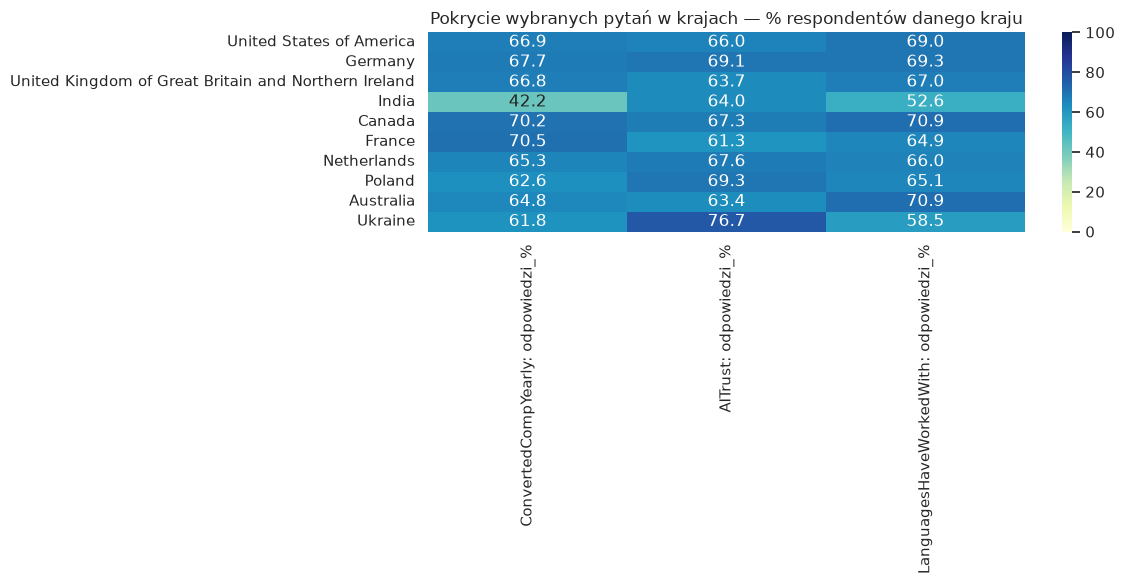

**Co nam to mówi?** Rozstęp pokrycia między pokazanymi krajami: ConvertedCompYearly: 28.4 p.p.; AITrust: 15.3 p.p.; LanguagesHaveWorkedWith: 18.2 p.p.. W dalszych analizach raportuj podstawę każdego zestawienia i porównaj profil osób z odpowiedzią oraz bez niej.

In [11]:
if 'Country' in df:
    top_countries = df.Country.value_counts().head(10).index
    rows = []
    for country in top_countries:
        part = df[df.Country.eq(country)]
        row = {'Country': country, 'respondenci_n': len(part)}
        for col in ['ConvertedCompYearly', 'AITrust', 'LanguagesHaveWorkedWith']:
            if col in part:
                row[f'{col}: odpowiedzi_%'] = part[col].notna().mean()*100
        rows.append(row)
    coverage_country = pd.DataFrame(rows).set_index('Country')
    display(coverage_country.round(1))
    measures = [col for col in coverage_country if col.endswith('odpowiedzi_%')]
    if measures:
        fig, ax = plt.subplots(figsize=(12, 6))
        sns.heatmap(coverage_country[measures], annot=True, fmt='.1f', cmap='YlGnBu', vmin=0,vmax=100,ax=ax)
        ax.set(title='Pokrycie wybranych pytań w krajach — % respondentów danego kraju', xlabel='', ylabel='')
        plt.tight_layout(); plt.show()
        spread = coverage_country[measures].max()-coverage_country[measures].min()
        note('Rozstęp pokrycia między pokazanymi krajami: ' + '; '.join(f'{k.split(":")[0]}: {v:.1f} p.p.' for k,v in spread.items()) +
             '. W dalszych analizach raportuj podstawę każdego zestawienia i porównaj profil osób z odpowiedzią oraz bez niej.')

## 10. Co już wiemy i od czego zacząć dalszą analizę?

Poniższe podsumowanie powstaje z wykonanych obliczeń, nie z założeń. Najpierw rozwiąż problemy jakości, potem formułuj hipotezy i dobieraj porównywalne grupy.

In [12]:
summary = [f'Próba zawiera **{N:,} rekordów i {P} pól**; udział braków w komórkach wynosi **{100*total_missing/(N*P):.1f}%**.']
if 'Country' in profiles and not profiles['Country'].empty:
    t = profiles['Country']
    summary.append(f'Najczęściej wskazywany kraj to **{t.index[0]}** ({t.iloc[0,1]:.1f}% odpowiadających na pytanie o kraj).')
if 'LanguagesHaveWorkedWith' in technology_tables and not technology_tables['LanguagesHaveWorkedWith'].empty:
    t = technology_tables['LanguagesHaveWorkedWith']
    summary.append(f'Najczęściej wskazywany używany język to **{t.index[0]}** ({t.iloc[0,1]:.1f}% odpowiadających na pytanie).')
if 'AITrust' in ai_tables and not ai_tables['AITrust'].empty:
    t = ai_tables['AITrust']
    summary.append(f'Najczęstsza deklaracja zaufania do AI to **{t.index[0]}** ({t.iloc[0,1]:.1f}% odpowiadających).')
display(Markdown('\n'.join(f'- {item}' for item in summary)))
display(Markdown("""### Plan kolejnego etapu

1. **Jakość i wersja eksportu:** wyjaśnić rozbieżności ze schematem, powtórzone ID, konwersje i skrajne kwoty; potwierdzić rok ankiety i źródło danych.
2. **Braki:** odtworzyć logikę pytań warunkowych. Nie zastępować braków zerem ani nie usuwać hurtowo wszystkich niekompletnych rekordów.
3. **Technologie:** porównać zainteresowanie i użycie w tych samych osobach, osobno według roli i stażu. Czy podobny wzorzec utrzymuje się w różnych grupach?
4. **AI:** sprawdzić związek zaufania z deklarowanym użyciem w porównywalnych rolach i grupach doświadczenia. Unikać interpretacji przyczynowej.
5. **Wynagrodzenia:** potwierdzić konwersję USD, zasady filtrowania i definicję wynagrodzenia; dopiero potem porównywać kraj, rolę i staż. Pokazać także analizę wrażliwości na skrajne wartości.
6. **Wnioskowanie:** przed testami ustalić hipotezy, efekty i minimalne liczebności. Przedziały ufności nie usuwają błędu doboru ochotniczej próby.
"""))

- Próba zawiera **30,903 rekordów i 212 pól**; udział braków w komórkach wynosi **70.6%**.
- Najczęściej wskazywany kraj to **United States of America** (22.3% odpowiadających na pytanie o kraj).
- Najczęściej wskazywany używany język to **JavaScript** (62.8% odpowiadających na pytanie).
- Najczęstsza deklaracja zaufania do AI to **I trust it when I can easily verify the output** (48.0% odpowiadających).

### Plan kolejnego etapu

1. **Jakość i wersja eksportu:** wyjaśnić rozbieżności ze schematem, powtórzone ID, konwersje i skrajne kwoty; potwierdzić rok ankiety i źródło danych.
2. **Braki:** odtworzyć logikę pytań warunkowych. Nie zastępować braków zerem ani nie usuwać hurtowo wszystkich niekompletnych rekordów.
3. **Technologie:** porównać zainteresowanie i użycie w tych samych osobach, osobno według roli i stażu. Czy podobny wzorzec utrzymuje się w różnych grupach?
4. **AI:** sprawdzić związek zaufania z deklarowanym użyciem w porównywalnych rolach i grupach doświadczenia. Unikać interpretacji przyczynowej.
5. **Wynagrodzenia:** potwierdzić konwersję USD, zasady filtrowania i definicję wynagrodzenia; dopiero potem porównywać kraj, rolę i staż. Pokazać także analizę wrażliwości na skrajne wartości.
6. **Wnioskowanie:** przed testami ustalić hipotezy, efekty i minimalne liczebności. Przedziały ufności nie usuwają błędu doboru ochotniczej próby.


## Aneks: powtarzalność

Identyfikatory SHA-256 pozwalają rozpoznać dokładnie tę wersję wejścia. Nie ujawniamy pojedynczych odpowiedzi. Notatnik nie zapisuje zmodyfikowanego CSV ani nie nadpisuje surowych danych.

In [13]:
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()
display(pd.DataFrame([{'plik':p.name, 'bajty':p.stat().st_size, 'sha256':sha256(p)} for p in paths]))
print('Python:', platform.python_version())
for package in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'nbclient']:
    print(f'{package}: {metadata.version(package)}')
assert raw.shape == df.shape, 'Nieoczekiwana zmiana rozmiaru danych'
print('Zakończono: dane źródłowe pozostały bez zmian; normalizacja dotyczyła wyłącznie białych znaków w kopii roboczej.')

,plik,bajty,sha256
0,survey_results_public.csv,122407316,ad520b4d5d71f240141e63f0d6f81a3b1898cbdc69efe9ea985496533b15fc2c
1,survey_results_schema.csv,93937,0892967cacdac5cdd1a7668de6f5edd8947bcc0ab204b7ec3e2d81084eb00b63


Python: 3.12.14
pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.18.1
nbclient: 0.11.0
Zakończono: dane źródłowe pozostały bez zmian; normalizacja dotyczyła wyłącznie białych znaków w kopii roboczej.
